# Data Analysis Notebook

## Import Libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools


from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # type: ignore

## Import Paths

In [11]:
from pathlib import Path
from utils.path_loader import load_paths
paths = load_paths()

PROJECT_ROOT = paths["project_root"]
# print(PROJECT_ROOT)

## Import Functions

In [ ]:
# # Exemplo de import de funções caso não está a a fazer reload por alguma razão
# import importlib
# import train_yolo.functions.yolo_results as results
# import train_yolo.functions.yolo_speed as speed

# # força reload real
# importlib.reload(results)  
# results.collect_models_results
# importlib.reload(speed) 
# speed.collect_models_speed


<module 'train_yolo.functions.yolo_results' from 'C:\\Users\\danie\\Desktop\\My_Things\\Hobbies\\VSCODE\\Virtual Envorinments\\CapStone\\src\\train_yolo\\functions\\yolo_results.py'>

<function train_yolo.functions.yolo_results.collect_models_results(models_root: pathlib.Path = WindowsPath('C:/Users/danie/Desktop/My_Things/Hobbies/VSCODE/Virtual Envorinments/CapStone/src/train_yolo'), verbose: bool = True) -> pandas.core.frame.DataFrame>

<module 'train_yolo.functions.yolo_speed' from 'C:\\Users\\danie\\Desktop\\My_Things\\Hobbies\\VSCODE\\Virtual Envorinments\\CapStone\\src\\train_yolo\\functions\\yolo_speed.py'>

<function train_yolo.functions.yolo_speed.collect_models_speed(models_root: pathlib.Path = WindowsPath('C:/Users/danie/Desktop/My_Things/Hobbies/VSCODE/Virtual Envorinments/CapStone/src/train_yolo'), num_images: int = 150, device: str | int = 'cpu')>

## Load the Data

In [ ]:
yolo_models_benchmarks_csv_path = PROJECT_ROOT / "reports"/"yolo"/"yolo_models_benchmarks.csv"

df_yolo = pd.read_csv(yolo_models_benchmarks_csv_path)
print("Head of the dataset:")
print(df_yolo.head())
print("\nColumns of the dataset:")
print(df_yolo.columns)

Head of the dataset:
  yolo_version         task     train_run  epochs_config  batch_config  \
0      yolo11s  skill_table  train-150e8b            150             8   
1      yolo11s  skill_table  train-150e4b            150             4   
2      yolo11s  skill_table  train-150e2b            150             2   
3      yolo11m   text-photo  train-150e8b            150             8   
4      yolo11m   text-photo  train-150e4b            150             4   

   best_epoch    mAP50  mAP50-95  precision   recall  val_box_loss  \
0         146  0.97745   0.85591    0.97727  0.96314       0.59987   
1         149  0.98565   0.84150    0.96532  0.96069       0.58958   
2          58  0.97690   0.78744    0.95756  0.94840       0.64472   
3         137  0.96288   0.88083    0.93996  0.94068       0.63244   
4         140  0.95996   0.87510    0.93518  0.94326       0.63579   

   val_cls_loss  val_dfl_loss  has_best_weights  \
0       0.40400       0.78381              True   
1       0.4

## 1. Yolo Models

### 1.1 Explore the Data

#### 1.1.1 Ordenar o dataset

In [15]:
df_yolo_sorted = df_yolo.sort_values("mAP50-95", ascending=False)

df_yolo_sorted

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,val_box_loss,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path
3,yolo11m,text-photo,train-150e8b,150,8,137,0.96288,0.88083,0.93996,0.94068,0.63244,0.40604,0.94324,True,src\train_yolo\yolo11m-text-photo\train-150e8b,31.209795,32.041223,150,0,src\train_yolo\yolo11m-text-photo\train-150e8b...
4,yolo11m,text-photo,train-150e4b,150,4,140,0.95996,0.87510,0.93518,0.94326,0.63579,0.38550,0.93975,True,src\train_yolo\yolo11m-text-photo\train-150e4b,32.599786,30.675048,150,0,src\train_yolo\yolo11m-text-photo\train-150e4b...
5,yolo11s,text-photo,train-150e2b,150,2,130,0.96380,0.87301,0.93939,0.94562,0.61990,0.42465,0.91354,True,src\train_yolo\yolo11s-text-photo\train-150e2b,18.565992,53.861922,150,0,src\train_yolo\yolo11s-text-photo\train-150e2b...
6,yolo11s,text-photo,train-150e6b,150,6,133,0.95890,0.87256,0.92871,0.94878,0.63772,0.42279,0.92648,True,src\train_yolo\yolo11s-text-photo\train-150e6b,18.836285,53.089024,150,0,src\train_yolo\yolo11s-text-photo\train-150e6b...
7,yolo11s,text-photo,train-150e14b,150,14,114,0.96047,0.87143,0.94053,0.93488,0.64074,0.41563,0.92860,True,src\train_yolo\yolo11s-text-photo\train-150e14b,18.811274,53.159612,150,0,src\train_yolo\yolo11s-text-photo\train-150e14...
8,yolo11s,text-photo,train-150e5b,150,5,117,0.96036,0.87128,0.93106,0.93994,0.63134,0.42985,0.91753,True,src\train_yolo\yolo11s-text-photo\train-150e5b,18.496869,54.063203,150,0,src\train_yolo\yolo11s-text-photo\train-150e5b...
9,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,0.62740,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,18.859312,53.024204,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...
10,yolo11s,text-photo,train-150e3b,150,3,135,0.95861,0.86808,0.93967,0.94819,0.62629,0.40905,0.91482,True,src\train_yolo\yolo11s-text-photo\train-150e3b,19.177721,52.143838,150,0,src\train_yolo\yolo11s-text-photo\train-150e3b...
11,yolo11s,text-photo,train-150e12b,150,12,130,0.95778,0.86745,0.92933,0.94657,0.64624,0.41473,0.92925,True,src\train_yolo\yolo11s-text-photo\train-150e12b,18.709593,53.448518,150,0,src\train_yolo\yolo11s-text-photo\train-150e12...
12,yolo11s,text-photo,train-150e11b,150,11,117,0.95745,0.86728,0.94080,0.93914,0.64704,0.41271,0.93839,True,src\train_yolo\yolo11s-text-photo\train-150e11b,18.752158,53.327194,150,0,src\train_yolo\yolo11s-text-photo\train-150e11...


#### 1.1.2 Dataset apenas para cada task:

In [16]:
# Text-photo
df_yolo_text_photo = df_yolo[df_yolo["task"] == "text-photo"].copy()

print("Runs text-photo:", len(df_yolo_text_photo))
df_yolo_text_photo

Runs text-photo: 20


,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,val_box_loss,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path
3,yolo11m,text-photo,train-150e8b,150,8,137,0.96288,0.88083,0.93996,0.94068,0.63244,0.40604,0.94324,True,src\train_yolo\yolo11m-text-photo\train-150e8b,31.209795,32.041223,150,0,src\train_yolo\yolo11m-text-photo\train-150e8b...
4,yolo11m,text-photo,train-150e4b,150,4,140,0.95996,0.87510,0.93518,0.94326,0.63579,0.38550,0.93975,True,src\train_yolo\yolo11m-text-photo\train-150e4b,32.599786,30.675048,150,0,src\train_yolo\yolo11m-text-photo\train-150e4b...
5,yolo11s,text-photo,train-150e2b,150,2,130,0.96380,0.87301,0.93939,0.94562,0.61990,0.42465,0.91354,True,src\train_yolo\yolo11s-text-photo\train-150e2b,18.565992,53.861922,150,0,src\train_yolo\yolo11s-text-photo\train-150e2b...
6,yolo11s,text-photo,train-150e6b,150,6,133,0.95890,0.87256,0.92871,0.94878,0.63772,0.42279,0.92648,True,src\train_yolo\yolo11s-text-photo\train-150e6b,18.836285,53.089024,150,0,src\train_yolo\yolo11s-text-photo\train-150e6b...
7,yolo11s,text-photo,train-150e14b,150,14,114,0.96047,0.87143,0.94053,0.93488,0.64074,0.41563,0.92860,True,src\train_yolo\yolo11s-text-photo\train-150e14b,18.811274,53.159612,150,0,src\train_yolo\yolo11s-text-photo\train-150e14...
8,yolo11s,text-photo,train-150e5b,150,5,117,0.96036,0.87128,0.93106,0.93994,0.63134,0.42985,0.91753,True,src\train_yolo\yolo11s-text-photo\train-150e5b,18.496869,54.063203,150,0,src\train_yolo\yolo11s-text-photo\train-150e5b...
9,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,0.62740,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,18.859312,53.024204,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...
10,yolo11s,text-photo,train-150e3b,150,3,135,0.95861,0.86808,0.93967,0.94819,0.62629,0.40905,0.91482,True,src\train_yolo\yolo11s-text-photo\train-150e3b,19.177721,52.143838,150,0,src\train_yolo\yolo11s-text-photo\train-150e3b...
11,yolo11s,text-photo,train-150e12b,150,12,130,0.95778,0.86745,0.92933,0.94657,0.64624,0.41473,0.92925,True,src\train_yolo\yolo11s-text-photo\train-150e12b,18.709593,53.448518,150,0,src\train_yolo\yolo11s-text-photo\train-150e12...
12,yolo11s,text-photo,train-150e11b,150,11,117,0.95745,0.86728,0.94080,0.93914,0.64704,0.41271,0.93839,True,src\train_yolo\yolo11s-text-photo\train-150e11b,18.752158,53.327194,150,0,src\train_yolo\yolo11s-text-photo\train-150e11...


In [17]:
# Skill_table
df_yolo_skill_table = df_yolo[df_yolo["task"] == "skill_table"].copy()

print("Runs skill_table:", len(df_yolo_skill_table))
df_yolo_skill_table

Runs skill_table: 3


,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,val_box_loss,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path
0,yolo11s,skill_table,train-150e8b,150,8,146,0.97745,0.85591,0.97727,0.96314,0.59987,0.40400,0.78381,True,src\train_yolo\yolo11s-skill_table\train-150e8b,17.020256,58.753524,150,0,src\train_yolo\yolo11s-skill_table\train-150e8...
1,yolo11s,skill_table,train-150e4b,150,4,149,0.98565,0.84150,0.96532,0.96069,0.58958,0.41314,0.74897,True,src\train_yolo\yolo11s-skill_table\train-150e4b,17.255584,57.952253,150,0,src\train_yolo\yolo11s-skill_table\train-150e4...
2,yolo11s,skill_table,train-150e2b,150,2,58,0.97690,0.78744,0.95756,0.94840,0.64472,0.59135,0.70755,True,src\train_yolo\yolo11s-skill_table\train-150e2b,19.392616,51.566019,150,0,src\train_yolo\yolo11s-skill_table\train-150e2...


#### 1.1.3 Dataset comparativo por batch
* task = text-photo
* batch = 4 e 8

In [18]:
df_yolo_text_photo_b4_b8 = df_yolo_text_photo[(df_yolo_text_photo["batch_config"].isin([4, 8]))].copy()

df_yolo_text_photo_b4_b8

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,val_box_loss,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path
3,yolo11m,text-photo,train-150e8b,150,8,137,0.96288,0.88083,0.93996,0.94068,0.63244,0.40604,0.94324,True,src\train_yolo\yolo11m-text-photo\train-150e8b,31.209795,32.041223,150,0,src\train_yolo\yolo11m-text-photo\train-150e8b...
4,yolo11m,text-photo,train-150e4b,150,4,140,0.95996,0.87510,0.93518,0.94326,0.63579,0.38550,0.93975,True,src\train_yolo\yolo11m-text-photo\train-150e4b,32.599786,30.675048,150,0,src\train_yolo\yolo11m-text-photo\train-150e4b...
9,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,0.62740,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,18.859312,53.024204,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...
13,yolo26s,text-photo,train-150e4b,150,4,98,0.95998,0.86721,0.91895,0.94110,0.65562,0.48420,0.00604,True,src\train_yolo\yolo26s-text-photo\train-150e4b,19.385619,51.584630,150,0,src\train_yolo\yolo26s-text-photo\train-150e4b...
14,yolo26s,text-photo,train-150e8b,150,8,111,0.95758,0.86676,0.93220,0.93017,0.66487,0.45587,0.00621,True,src\train_yolo\yolo26s-text-photo\train-150e8b,19.985476,50.036338,150,0,src\train_yolo\yolo26s-text-photo\train-150e8b...
15,yolo11s,text-photo,train-150e8b,150,8,69,0.96007,0.86504,0.92560,0.94386,0.62551,0.44502,0.91580,True,src\train_yolo\yolo11s-text-photo\train-150e8b,18.795126,53.205282,150,0,src\train_yolo\yolo11s-text-photo\train-150e8b...
18,yolov8s,text-photo,train-150e4b,150,4,113,0.95552,0.86371,0.92931,0.93589,0.62814,0.43453,0.92278,True,src\train_yolo\yolov8s-text-photo\train-150e4b,18.946703,52.779631,150,0,src\train_yolo\yolov8s-text-photo\train-150e4b...
22,yolov8s,text-photo,train-150e8b,150,8,93,0.95999,0.86062,0.92113,0.93869,0.65075,0.45245,0.93759,True,src\train_yolo\yolov8s-text-photo\train-150e8b,19.447989,51.419197,150,0,src\train_yolo\yolov8s-text-photo\train-150e8b...


#### 1.1.4 Dataset apenas para text-photo e yolo11s

In [19]:
df_yolo_text_photo_yolo11s = df_yolo_text_photo[df_yolo_text_photo["yolo_version"] == "yolo11s"].copy()

df_yolo_text_photo_yolo11s

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,val_box_loss,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path
5,yolo11s,text-photo,train-150e2b,150,2,130,0.96380,0.87301,0.93939,0.94562,0.61990,0.42465,0.91354,True,src\train_yolo\yolo11s-text-photo\train-150e2b,18.565992,53.861922,150,0,src\train_yolo\yolo11s-text-photo\train-150e2b...
6,yolo11s,text-photo,train-150e6b,150,6,133,0.95890,0.87256,0.92871,0.94878,0.63772,0.42279,0.92648,True,src\train_yolo\yolo11s-text-photo\train-150e6b,18.836285,53.089024,150,0,src\train_yolo\yolo11s-text-photo\train-150e6b...
7,yolo11s,text-photo,train-150e14b,150,14,114,0.96047,0.87143,0.94053,0.93488,0.64074,0.41563,0.92860,True,src\train_yolo\yolo11s-text-photo\train-150e14b,18.811274,53.159612,150,0,src\train_yolo\yolo11s-text-photo\train-150e14...
8,yolo11s,text-photo,train-150e5b,150,5,117,0.96036,0.87128,0.93106,0.93994,0.63134,0.42985,0.91753,True,src\train_yolo\yolo11s-text-photo\train-150e5b,18.496869,54.063203,150,0,src\train_yolo\yolo11s-text-photo\train-150e5b...
9,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,0.62740,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,18.859312,53.024204,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...
10,yolo11s,text-photo,train-150e3b,150,3,135,0.95861,0.86808,0.93967,0.94819,0.62629,0.40905,0.91482,True,src\train_yolo\yolo11s-text-photo\train-150e3b,19.177721,52.143838,150,0,src\train_yolo\yolo11s-text-photo\train-150e3b...
11,yolo11s,text-photo,train-150e12b,150,12,130,0.95778,0.86745,0.92933,0.94657,0.64624,0.41473,0.92925,True,src\train_yolo\yolo11s-text-photo\train-150e12b,18.709593,53.448518,150,0,src\train_yolo\yolo11s-text-photo\train-150e12...
12,yolo11s,text-photo,train-150e11b,150,11,117,0.95745,0.86728,0.94080,0.93914,0.64704,0.41271,0.93839,True,src\train_yolo\yolo11s-text-photo\train-150e11b,18.752158,53.327194,150,0,src\train_yolo\yolo11s-text-photo\train-150e11...
15,yolo11s,text-photo,train-150e8b,150,8,69,0.96007,0.86504,0.92560,0.94386,0.62551,0.44502,0.91580,True,src\train_yolo\yolo11s-text-photo\train-150e8b,18.795126,53.205282,150,0,src\train_yolo\yolo11s-text-photo\train-150e8b...
16,yolo11s,text-photo,train-150e7b,150,7,122,0.95383,0.86491,0.92014,0.95578,0.64016,0.42323,0.92433,True,src\train_yolo\yolo11s-text-photo\train-150e7b,18.756758,53.314116,150,0,src\train_yolo\yolo11s-text-photo\train-150e7b...


#### 1.1.5 Ordenar cada sub-dataset

In [20]:
df_yolo_text_photo_sorted = df_yolo_text_photo.sort_values("mAP50-95", ascending=False)
df_yolo_skill_table_sorted = df_yolo_skill_table.sort_values("mAP50-95", ascending=False)
df_yolo_text_photo_b4_b8_sorted = df_yolo_text_photo_b4_b8.sort_values("mAP50-95", ascending=False)
df_yolo_text_photo_yolo11s_sorted = df_yolo_text_photo_yolo11s.sort_values("mAP50-95", ascending=False)

In [21]:
df_yolo_text_photo_sorted

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,val_box_loss,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path
3,yolo11m,text-photo,train-150e8b,150,8,137,0.96288,0.88083,0.93996,0.94068,0.63244,0.40604,0.94324,True,src\train_yolo\yolo11m-text-photo\train-150e8b,31.209795,32.041223,150,0,src\train_yolo\yolo11m-text-photo\train-150e8b...
4,yolo11m,text-photo,train-150e4b,150,4,140,0.95996,0.87510,0.93518,0.94326,0.63579,0.38550,0.93975,True,src\train_yolo\yolo11m-text-photo\train-150e4b,32.599786,30.675048,150,0,src\train_yolo\yolo11m-text-photo\train-150e4b...
5,yolo11s,text-photo,train-150e2b,150,2,130,0.96380,0.87301,0.93939,0.94562,0.61990,0.42465,0.91354,True,src\train_yolo\yolo11s-text-photo\train-150e2b,18.565992,53.861922,150,0,src\train_yolo\yolo11s-text-photo\train-150e2b...
6,yolo11s,text-photo,train-150e6b,150,6,133,0.95890,0.87256,0.92871,0.94878,0.63772,0.42279,0.92648,True,src\train_yolo\yolo11s-text-photo\train-150e6b,18.836285,53.089024,150,0,src\train_yolo\yolo11s-text-photo\train-150e6b...
7,yolo11s,text-photo,train-150e14b,150,14,114,0.96047,0.87143,0.94053,0.93488,0.64074,0.41563,0.92860,True,src\train_yolo\yolo11s-text-photo\train-150e14b,18.811274,53.159612,150,0,src\train_yolo\yolo11s-text-photo\train-150e14...
8,yolo11s,text-photo,train-150e5b,150,5,117,0.96036,0.87128,0.93106,0.93994,0.63134,0.42985,0.91753,True,src\train_yolo\yolo11s-text-photo\train-150e5b,18.496869,54.063203,150,0,src\train_yolo\yolo11s-text-photo\train-150e5b...
9,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,0.62740,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,18.859312,53.024204,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...
10,yolo11s,text-photo,train-150e3b,150,3,135,0.95861,0.86808,0.93967,0.94819,0.62629,0.40905,0.91482,True,src\train_yolo\yolo11s-text-photo\train-150e3b,19.177721,52.143838,150,0,src\train_yolo\yolo11s-text-photo\train-150e3b...
11,yolo11s,text-photo,train-150e12b,150,12,130,0.95778,0.86745,0.92933,0.94657,0.64624,0.41473,0.92925,True,src\train_yolo\yolo11s-text-photo\train-150e12b,18.709593,53.448518,150,0,src\train_yolo\yolo11s-text-photo\train-150e12...
12,yolo11s,text-photo,train-150e11b,150,11,117,0.95745,0.86728,0.94080,0.93914,0.64704,0.41271,0.93839,True,src\train_yolo\yolo11s-text-photo\train-150e11b,18.752158,53.327194,150,0,src\train_yolo\yolo11s-text-photo\train-150e11...


In [22]:
df_yolo_skill_table_sorted

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,val_box_loss,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path
0,yolo11s,skill_table,train-150e8b,150,8,146,0.97745,0.85591,0.97727,0.96314,0.59987,0.40400,0.78381,True,src\train_yolo\yolo11s-skill_table\train-150e8b,17.020256,58.753524,150,0,src\train_yolo\yolo11s-skill_table\train-150e8...
1,yolo11s,skill_table,train-150e4b,150,4,149,0.98565,0.84150,0.96532,0.96069,0.58958,0.41314,0.74897,True,src\train_yolo\yolo11s-skill_table\train-150e4b,17.255584,57.952253,150,0,src\train_yolo\yolo11s-skill_table\train-150e4...
2,yolo11s,skill_table,train-150e2b,150,2,58,0.97690,0.78744,0.95756,0.94840,0.64472,0.59135,0.70755,True,src\train_yolo\yolo11s-skill_table\train-150e2b,19.392616,51.566019,150,0,src\train_yolo\yolo11s-skill_table\train-150e2...


In [23]:
df_yolo_text_photo_b4_b8_sorted

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,val_box_loss,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path
3,yolo11m,text-photo,train-150e8b,150,8,137,0.96288,0.88083,0.93996,0.94068,0.63244,0.40604,0.94324,True,src\train_yolo\yolo11m-text-photo\train-150e8b,31.209795,32.041223,150,0,src\train_yolo\yolo11m-text-photo\train-150e8b...
4,yolo11m,text-photo,train-150e4b,150,4,140,0.95996,0.87510,0.93518,0.94326,0.63579,0.38550,0.93975,True,src\train_yolo\yolo11m-text-photo\train-150e4b,32.599786,30.675048,150,0,src\train_yolo\yolo11m-text-photo\train-150e4b...
9,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,0.62740,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,18.859312,53.024204,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...
13,yolo26s,text-photo,train-150e4b,150,4,98,0.95998,0.86721,0.91895,0.94110,0.65562,0.48420,0.00604,True,src\train_yolo\yolo26s-text-photo\train-150e4b,19.385619,51.584630,150,0,src\train_yolo\yolo26s-text-photo\train-150e4b...
14,yolo26s,text-photo,train-150e8b,150,8,111,0.95758,0.86676,0.93220,0.93017,0.66487,0.45587,0.00621,True,src\train_yolo\yolo26s-text-photo\train-150e8b,19.985476,50.036338,150,0,src\train_yolo\yolo26s-text-photo\train-150e8b...
15,yolo11s,text-photo,train-150e8b,150,8,69,0.96007,0.86504,0.92560,0.94386,0.62551,0.44502,0.91580,True,src\train_yolo\yolo11s-text-photo\train-150e8b,18.795126,53.205282,150,0,src\train_yolo\yolo11s-text-photo\train-150e8b...
18,yolov8s,text-photo,train-150e4b,150,4,113,0.95552,0.86371,0.92931,0.93589,0.62814,0.43453,0.92278,True,src\train_yolo\yolov8s-text-photo\train-150e4b,18.946703,52.779631,150,0,src\train_yolo\yolov8s-text-photo\train-150e4b...
22,yolov8s,text-photo,train-150e8b,150,8,93,0.95999,0.86062,0.92113,0.93869,0.65075,0.45245,0.93759,True,src\train_yolo\yolov8s-text-photo\train-150e8b,19.447989,51.419197,150,0,src\train_yolo\yolov8s-text-photo\train-150e8b...


In [24]:
df_yolo_text_photo_yolo11s_sorted

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,val_box_loss,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path
5,yolo11s,text-photo,train-150e2b,150,2,130,0.96380,0.87301,0.93939,0.94562,0.61990,0.42465,0.91354,True,src\train_yolo\yolo11s-text-photo\train-150e2b,18.565992,53.861922,150,0,src\train_yolo\yolo11s-text-photo\train-150e2b...
6,yolo11s,text-photo,train-150e6b,150,6,133,0.95890,0.87256,0.92871,0.94878,0.63772,0.42279,0.92648,True,src\train_yolo\yolo11s-text-photo\train-150e6b,18.836285,53.089024,150,0,src\train_yolo\yolo11s-text-photo\train-150e6b...
7,yolo11s,text-photo,train-150e14b,150,14,114,0.96047,0.87143,0.94053,0.93488,0.64074,0.41563,0.92860,True,src\train_yolo\yolo11s-text-photo\train-150e14b,18.811274,53.159612,150,0,src\train_yolo\yolo11s-text-photo\train-150e14...
8,yolo11s,text-photo,train-150e5b,150,5,117,0.96036,0.87128,0.93106,0.93994,0.63134,0.42985,0.91753,True,src\train_yolo\yolo11s-text-photo\train-150e5b,18.496869,54.063203,150,0,src\train_yolo\yolo11s-text-photo\train-150e5b...
9,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,0.62740,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,18.859312,53.024204,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...
10,yolo11s,text-photo,train-150e3b,150,3,135,0.95861,0.86808,0.93967,0.94819,0.62629,0.40905,0.91482,True,src\train_yolo\yolo11s-text-photo\train-150e3b,19.177721,52.143838,150,0,src\train_yolo\yolo11s-text-photo\train-150e3b...
11,yolo11s,text-photo,train-150e12b,150,12,130,0.95778,0.86745,0.92933,0.94657,0.64624,0.41473,0.92925,True,src\train_yolo\yolo11s-text-photo\train-150e12b,18.709593,53.448518,150,0,src\train_yolo\yolo11s-text-photo\train-150e12...
12,yolo11s,text-photo,train-150e11b,150,11,117,0.95745,0.86728,0.94080,0.93914,0.64704,0.41271,0.93839,True,src\train_yolo\yolo11s-text-photo\train-150e11b,18.752158,53.327194,150,0,src\train_yolo\yolo11s-text-photo\train-150e11...
15,yolo11s,text-photo,train-150e8b,150,8,69,0.96007,0.86504,0.92560,0.94386,0.62551,0.44502,0.91580,True,src\train_yolo\yolo11s-text-photo\train-150e8b,18.795126,53.205282,150,0,src\train_yolo\yolo11s-text-photo\train-150e8b...
16,yolo11s,text-photo,train-150e7b,150,7,122,0.95383,0.86491,0.92014,0.95578,0.64016,0.42323,0.92433,True,src\train_yolo\yolo11s-text-photo\train-150e7b,18.756758,53.314116,150,0,src\train_yolo\yolo11s-text-photo\train-150e7b...


#### 1.1.6 Melhor modelo por sub-dataset

In [25]:
def print_best_model(title: str, row):
    print("=" * 60)
    print(title)
    print("-" * 60)
    print(f"YOLO version : {row['yolo_version']}")
    print(f"Task         : {row['task']}")
    print(f"Train run    : {row['train_run']}")
    print(f"Epochs cfg   : {row['epochs_config']}")
    print(f"Batch cfg    : {row['batch_config']}")
    print(f"Best epoch   : {row['best_epoch']}")
    print()
    print(f"mAP50        : {row['mAP50']:.4f}")
    print(f"mAP50-95     : {row['mAP50-95']:.4f}")
    print(f"Precision    : {row['precision']:.4f}")
    print(f"Recall       : {row['recall']:.4f}")
    print("=" * 60)
    print()


In [26]:
best_yolo_text_photo = df_yolo_text_photo_sorted.iloc[0]
best_yolo_text_photo_b4_b8 = df_yolo_text_photo_b4_b8_sorted.iloc[0]
best_yolo_text_photo_yolo11s = df_yolo_text_photo_yolo11s_sorted.iloc[0]
best_yolo_skill_table = df_yolo_skill_table_sorted.iloc[0]

In [27]:
print_best_model("BEST MODEL — TEXT-PHOTO (GLOBAL)", best_yolo_text_photo)
print_best_model("BEST MODEL — TEXT-PHOTO (BATCH 4 vs 8)", best_yolo_text_photo_b4_b8)
print_best_model("BEST MODEL — TEXT-PHOTO (YOLO11s)", best_yolo_text_photo_yolo11s)
print_best_model("BEST MODEL — SKILL TABLE", best_yolo_skill_table)

BEST MODEL — TEXT-PHOTO (GLOBAL)
------------------------------------------------------------
YOLO version : yolo11m
Task         : text-photo
Train run    : train-150e8b
Epochs cfg   : 150
Batch cfg    : 8
Best epoch   : 137

mAP50        : 0.9629
mAP50-95     : 0.8808
Precision    : 0.9400
Recall       : 0.9407

BEST MODEL — TEXT-PHOTO (BATCH 4 vs 8)
------------------------------------------------------------
YOLO version : yolo11m
Task         : text-photo
Train run    : train-150e8b
Epochs cfg   : 150
Batch cfg    : 8
Best epoch   : 137

mAP50        : 0.9629
mAP50-95     : 0.8808
Precision    : 0.9400
Recall       : 0.9407

BEST MODEL — TEXT-PHOTO (YOLO11s)
------------------------------------------------------------
YOLO version : yolo11s
Task         : text-photo
Train run    : train-150e2b
Epochs cfg   : 150
Batch cfg    : 2
Best epoch   : 130

mAP50        : 0.9638
mAP50-95     : 0.8730
Precision    : 0.9394
Recall       : 0.9456

BEST MODEL — SKILL TABLE
--------------------

#### 1.1.6 Average per YOLO version for text-photo and batch 4 and 8 only.

In [28]:
df_yolo_text_photo_b4_b8.groupby("yolo_version")["mAP50-95"].mean().sort_values(ascending=False)

yolo_version
yolo11m    0.877965
yolo11s    0.867915
yolo26s    0.866985
yolov8s    0.862165
Name: mAP50-95, dtype: float64

#### 1.1.7 Dividing categorical and numerical variables

In [31]:
# Device is categorical because it can be 0 or "cpu"
df_yolo["device"] = df_yolo["device"].astype("object")

In [32]:
numeric_cols_yolo = df_yolo.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols_yolo = df_yolo.select_dtypes(include=['object']).columns.tolist()

numeric_cols_yolo, categorical_cols_yolo

(['epochs_config',
  'batch_config',
  'best_epoch',
  'mAP50',
  'mAP50-95',
  'precision',
  'recall',
  'val_box_loss',
  'val_cls_loss',
  'val_dfl_loss',
  'ms_per_image',
  'fps',
  'num_images'],
 ['yolo_version', 'task', 'train_run', 'run_path', 'device', 'model_path'])

### 1.2 Graphics

#### 1.2.1 Graph of the distribution of numerical variables

array([[<Axes: title={'center': 'epochs_config'}>, <Axes: title={'center': 'batch_config'}>, <Axes: title={'center': 'best_epoch'}>, <Axes: title={'center': 'mAP50'}>],
       [<Axes: title={'center': 'mAP50-95'}>, <Axes: title={'center': 'precision'}>, <Axes: title={'center': 'recall'}>, <Axes: title={'center': 'val_box_loss'}>],
       [<Axes: title={'center': 'val_cls_loss'}>, <Axes: title={'center': 'val_dfl_loss'}>, <Axes: title={'center': 'ms_per_image'}>, <Axes: title={'center': 'fps'}>],
       [<Axes: title={'center': 'num_images'}>, <Axes: >, <Axes: >, <Axes: >]], dtype=object)

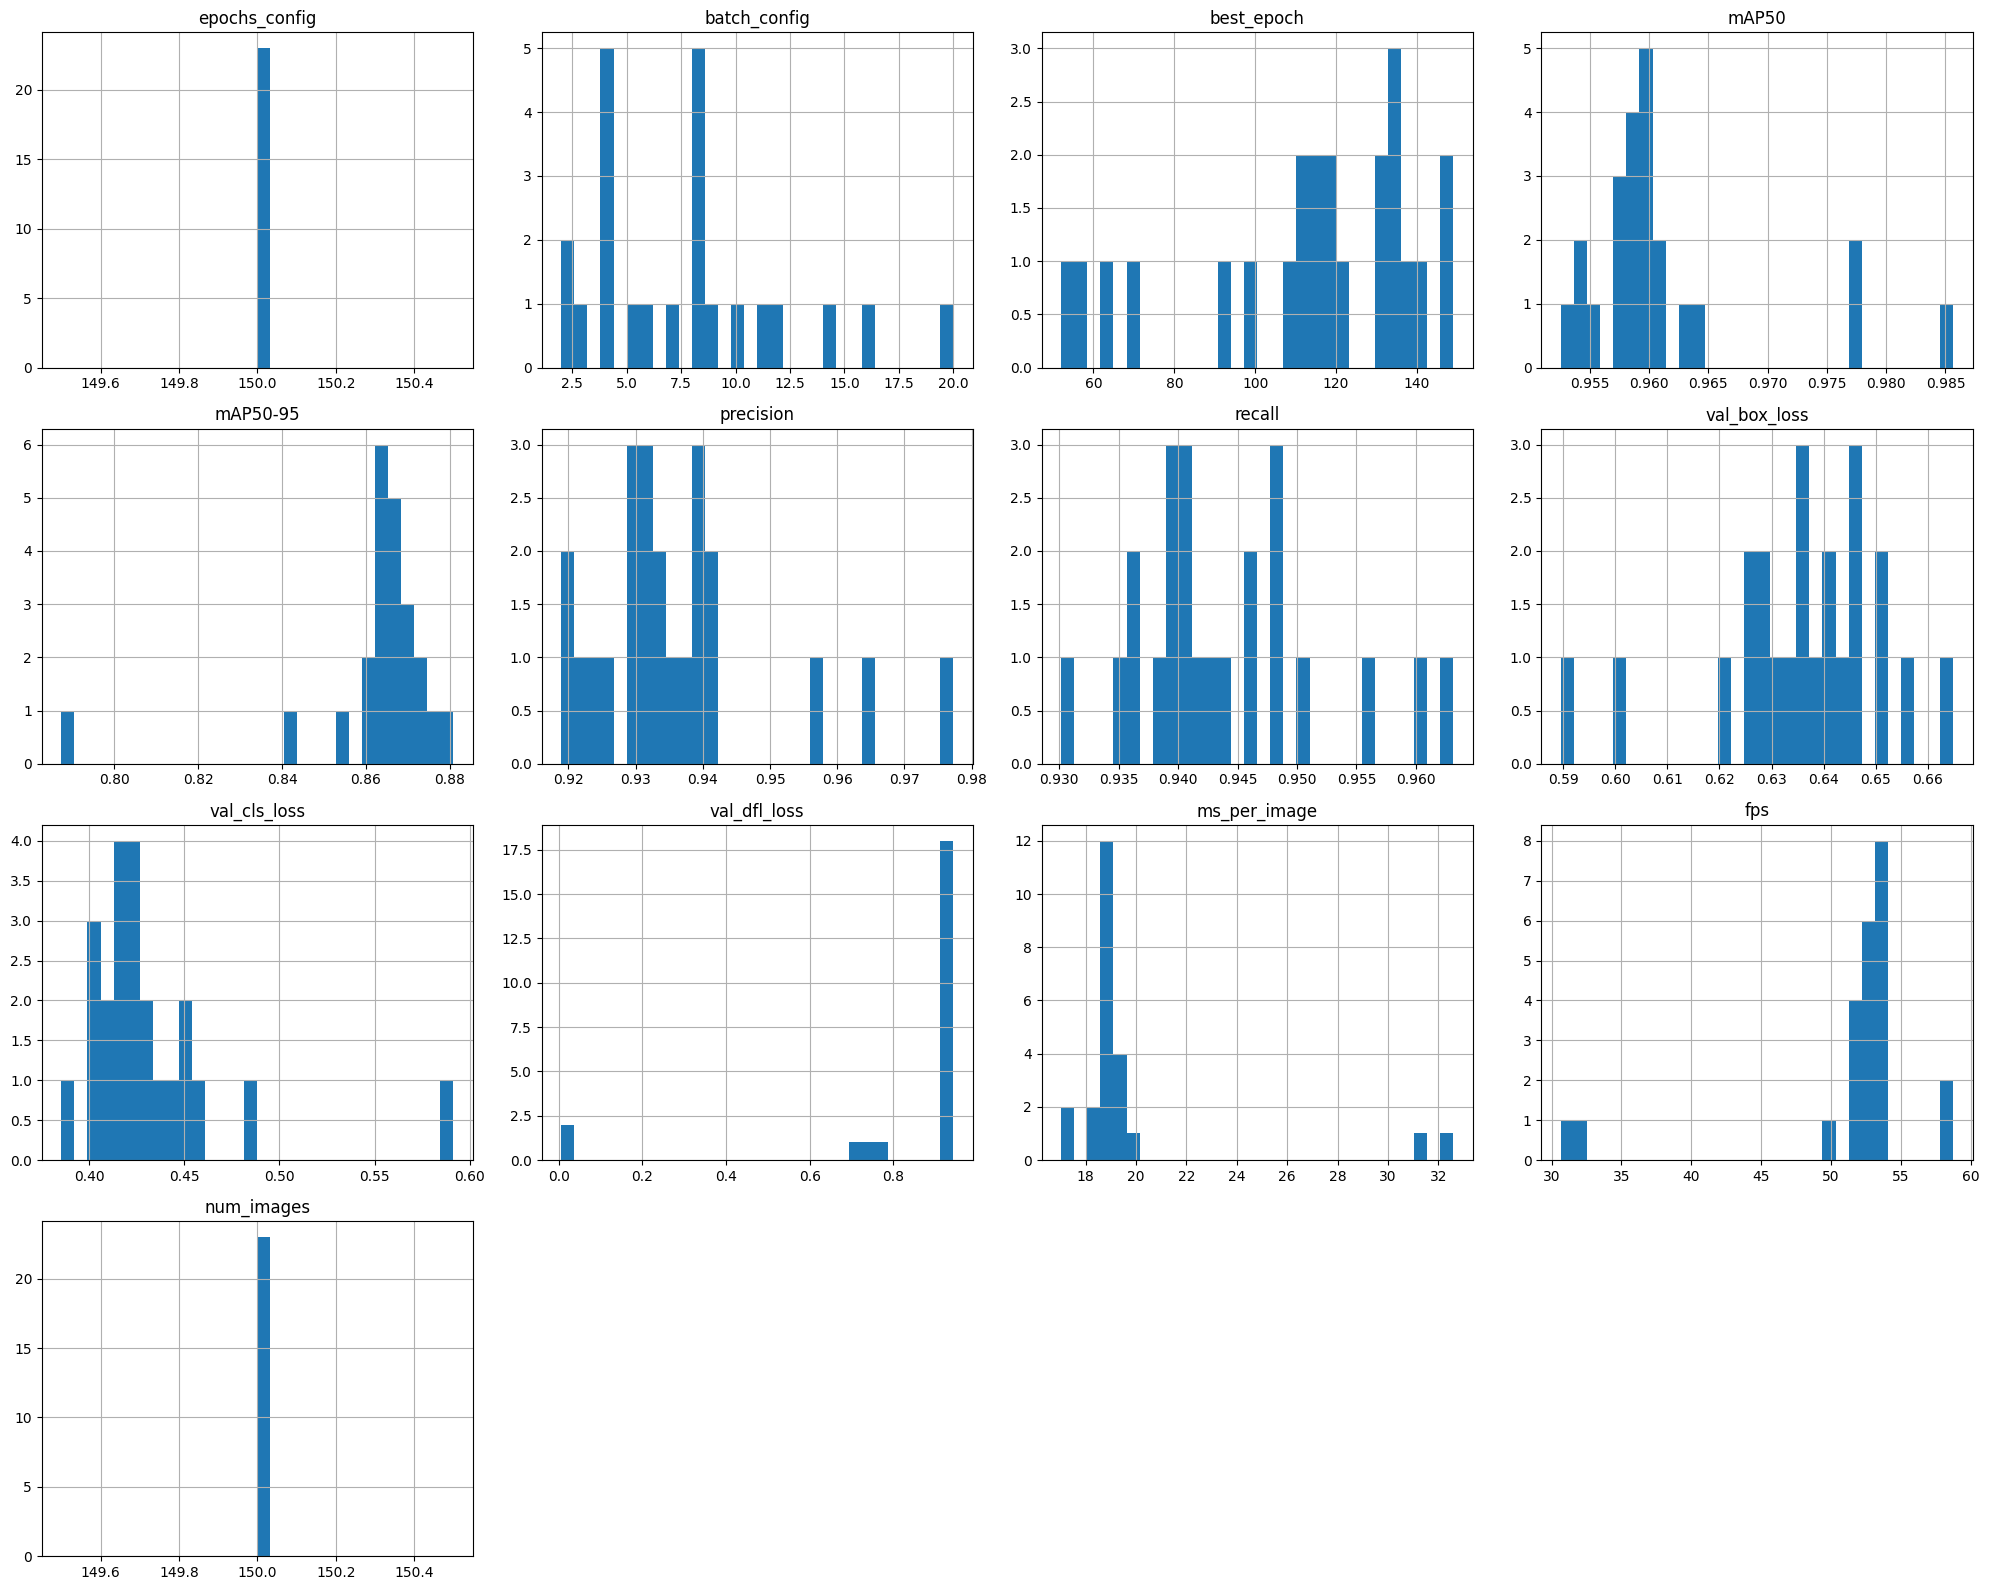

In [33]:
df_yolo[numeric_cols_yolo].hist(figsize=(20,16), bins=30)
plt.tight_layout()
plt.show()

#### 1.2.2 YOLO benchmark chart

In [57]:
def plot_yolo_vs_batch(df, y_col, x_col="batch_config", title=None, df_name=None):
    """
    Plota benchmark YOLO:
    X -> coluna escolhida (x_col)
    Y -> coluna escolhida (y_col)
    Linha -> yolo_version
    """

    # ordenar pelos valores de X
    df_plot = df.sort_values(x_col)

    plt.figure(figsize=(11, 6))

    # linhas por versão YOLO
    for version, group in df_plot.groupby("yolo_version"):
        plt.plot(
            group[x_col],
            group[y_col],
            marker="o",
            markersize=7,
            linewidth=2.5,
            label=version
        )

    # --- ticks discretos se X for inteiro ---
    if pd.api.types.is_numeric_dtype(df_plot[x_col]):
        xmin = df_plot[x_col].min()
        xmax = df_plot[x_col].max()

        # só faz ticks 1-a-1 se parecer inteiro
        if float(xmin).is_integer() and float(xmax).is_integer():
            plt.xticks(np.arange(int(xmin), int(xmax) + 1, 1))

    # --- limites Y bonitos ---
    ymin = df_plot[y_col].min()
    ymax = df_plot[y_col].max()
    margin = (ymax - ymin) * 0.05 if ymax != ymin else 0.01
    plt.ylim(ymin - margin, ymax + margin)

    # labels
    plt.xlabel(x_col, fontsize=12)
    plt.ylabel(y_col, fontsize=12)

    # título automático
    if title is None:
        base = f"YOLO Benchmark: {y_col} vs {x_col}"
        title = f"{base} ({df_name})" if df_name else base

    plt.title(title, fontsize=14, weight="bold")

    plt.grid(True, linestyle="--", alpha=0.3)
    plt.legend(title="YOLO version")

    plt.tight_layout()
    plt.show()


mAP50-95 vs batch

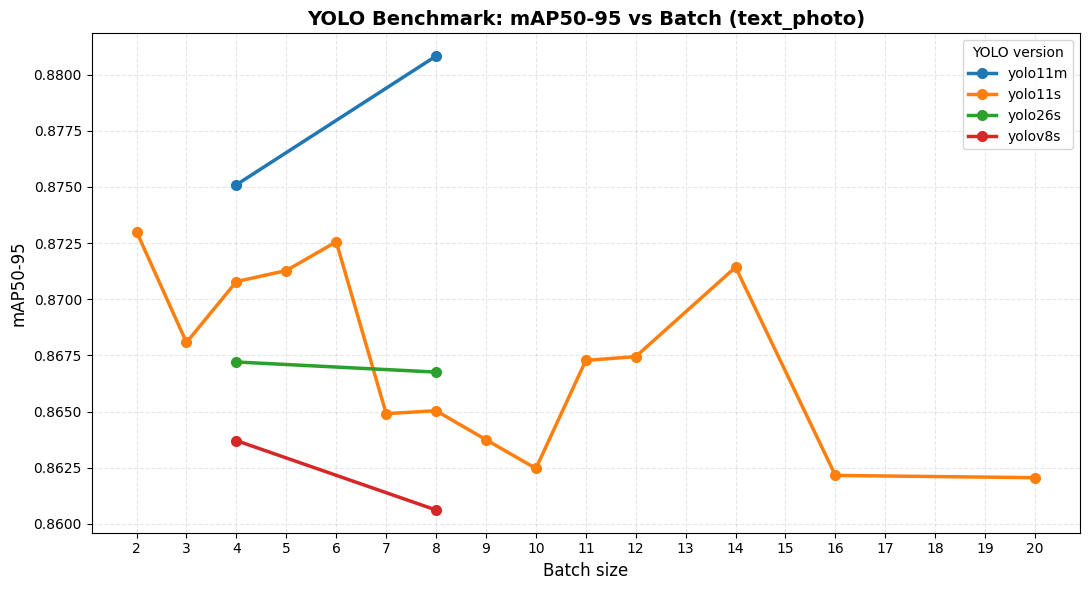

In [47]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50-95", df_name= "text_photo")

mAP50 vs batch

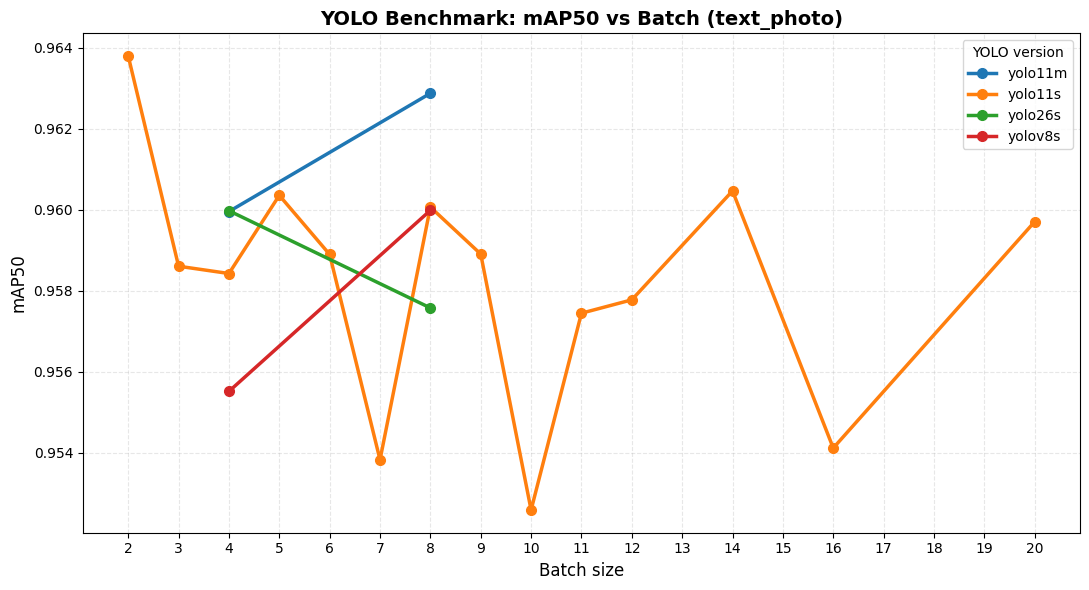

In [48]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50", df_name= "text_photo")

Precision vs batch

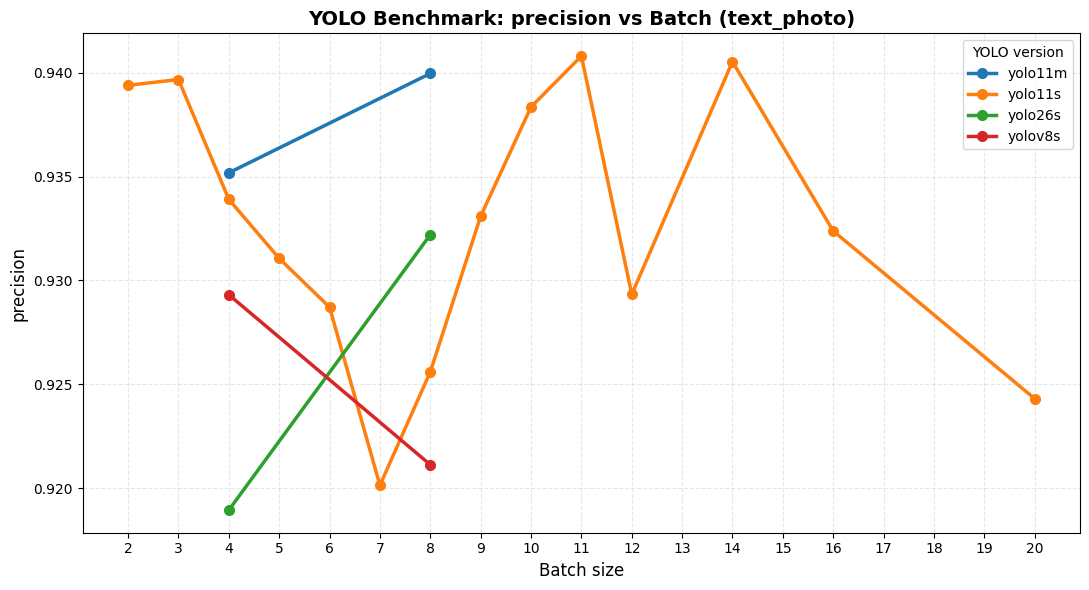

In [49]:
plot_yolo_vs_batch(df_yolo_text_photo, "precision", df_name= "text_photo")

Recall vs batch

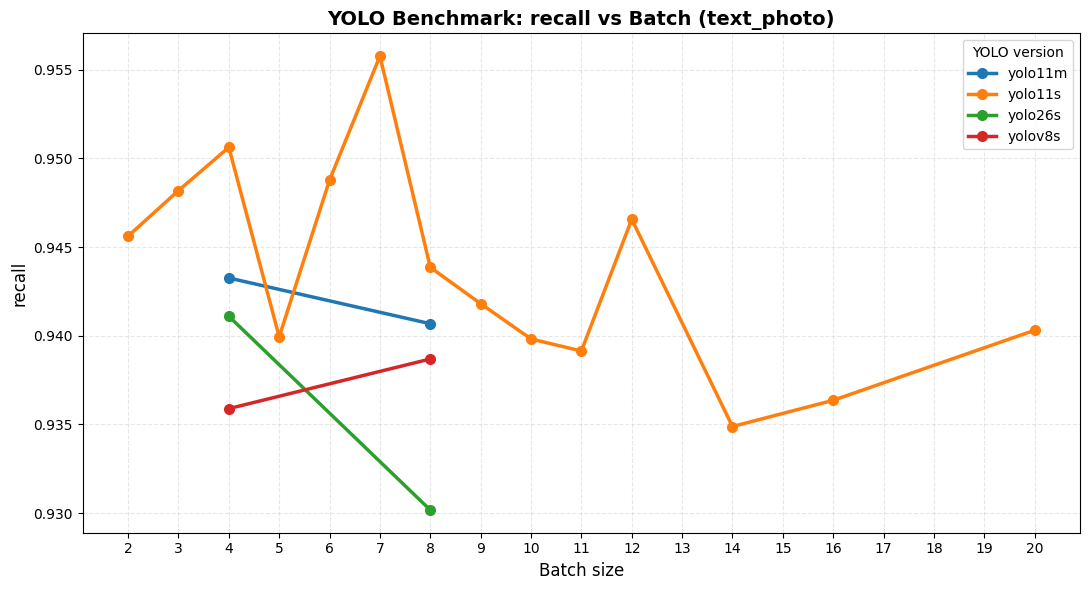

In [51]:
plot_yolo_vs_batch(df_yolo_text_photo, "recall", df_name= "text_photo")

Val_box_loss vs batch

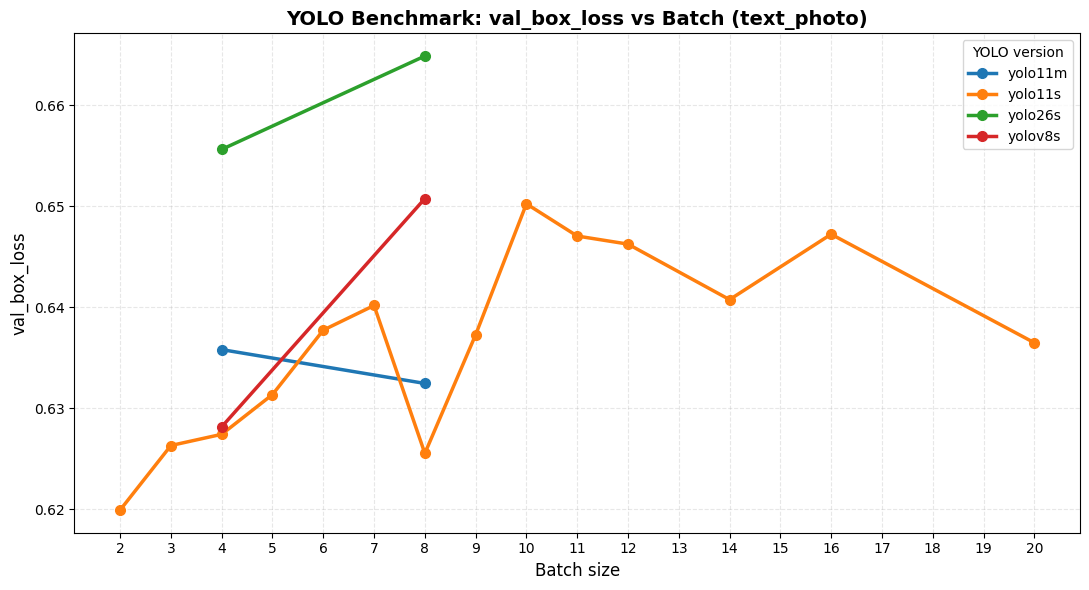

In [52]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_box_loss", df_name= "text_photo")

Val_cls_loss vs batch

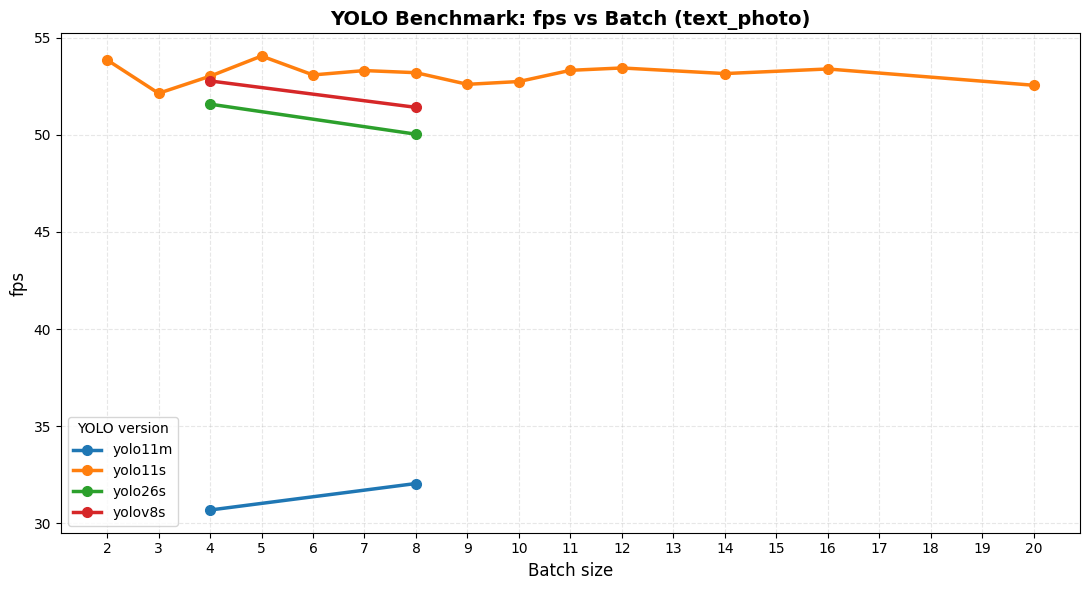

In [ ]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_cls_loss", df_name= "text_photo")

Val_dfl_loss vs batch

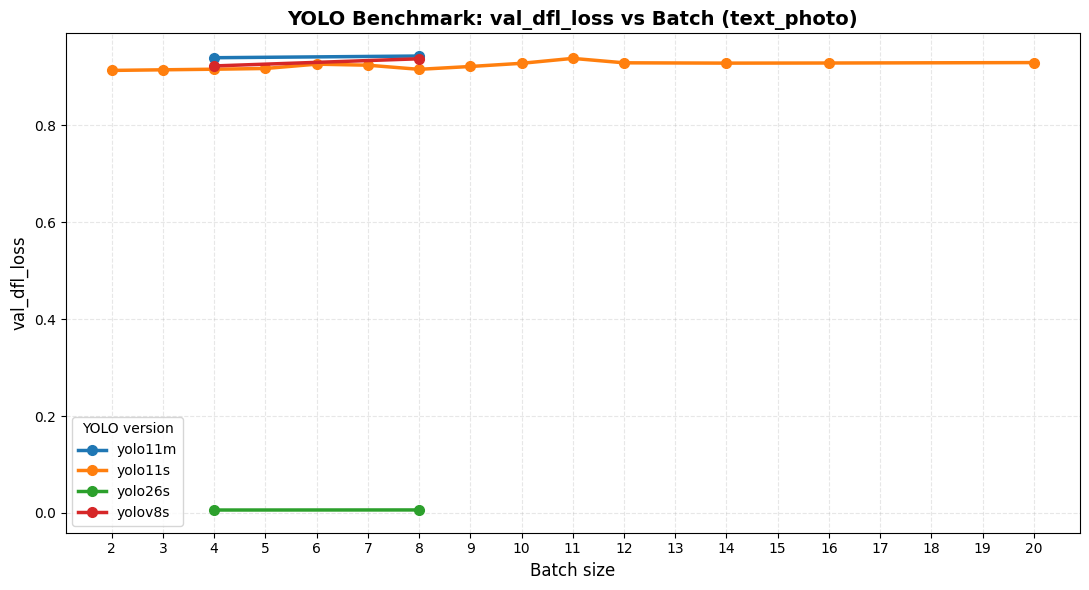

In [53]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_dfl_loss", df_name= "text_photo")

FPS vs batch

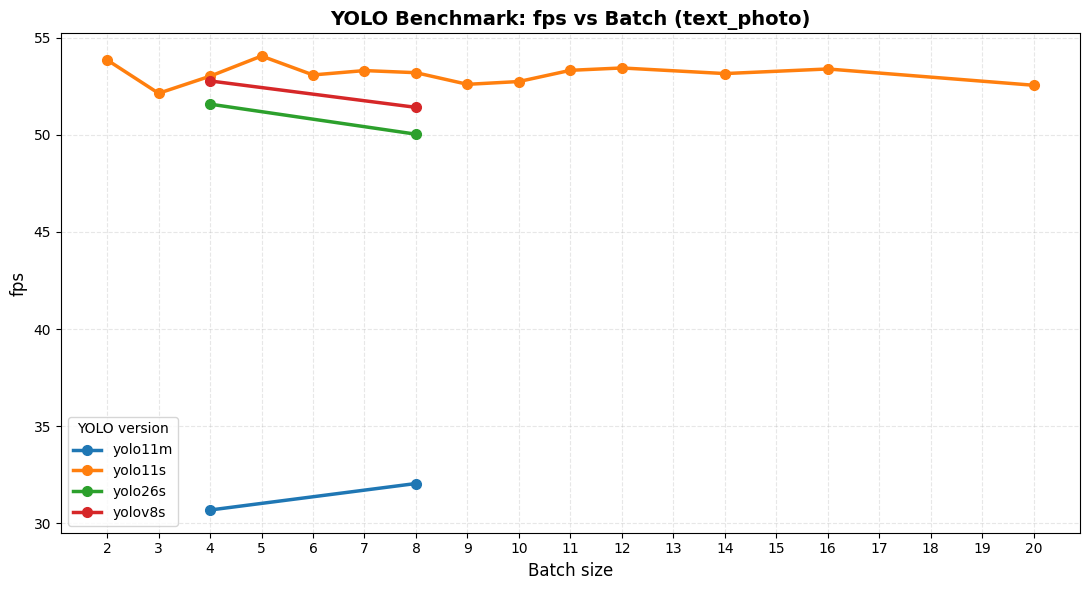

In [50]:
plot_yolo_vs_batch(df_yolo_text_photo, "fps", df_name= "text_photo")

Ms_per_image vs batch

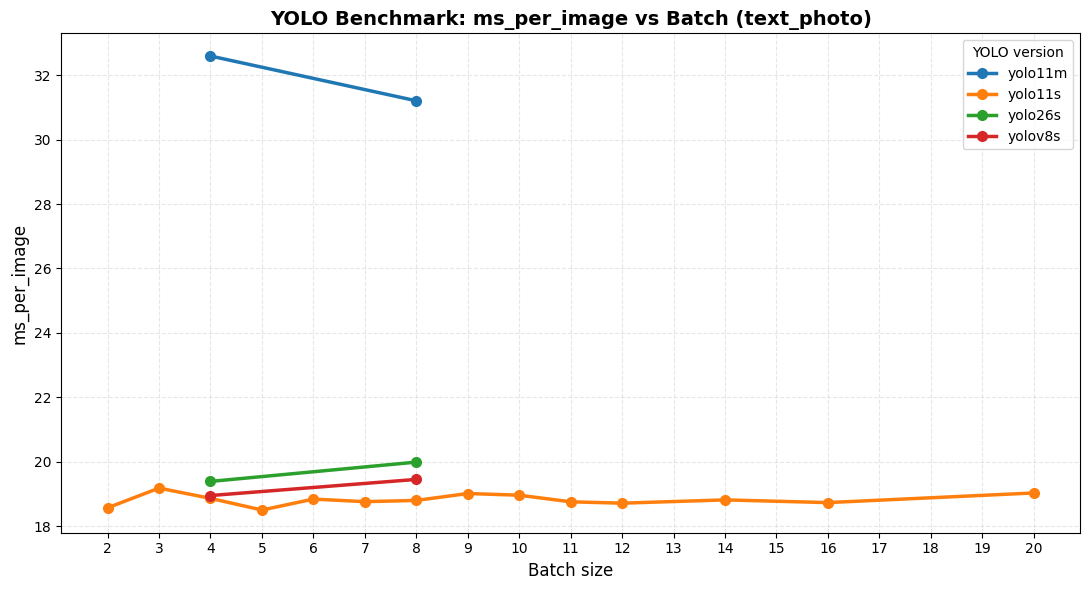

In [54]:
plot_yolo_vs_batch(df_yolo_text_photo, "ms_per_image", df_name= "text_photo")

mAP50-95 vs ms_per_image

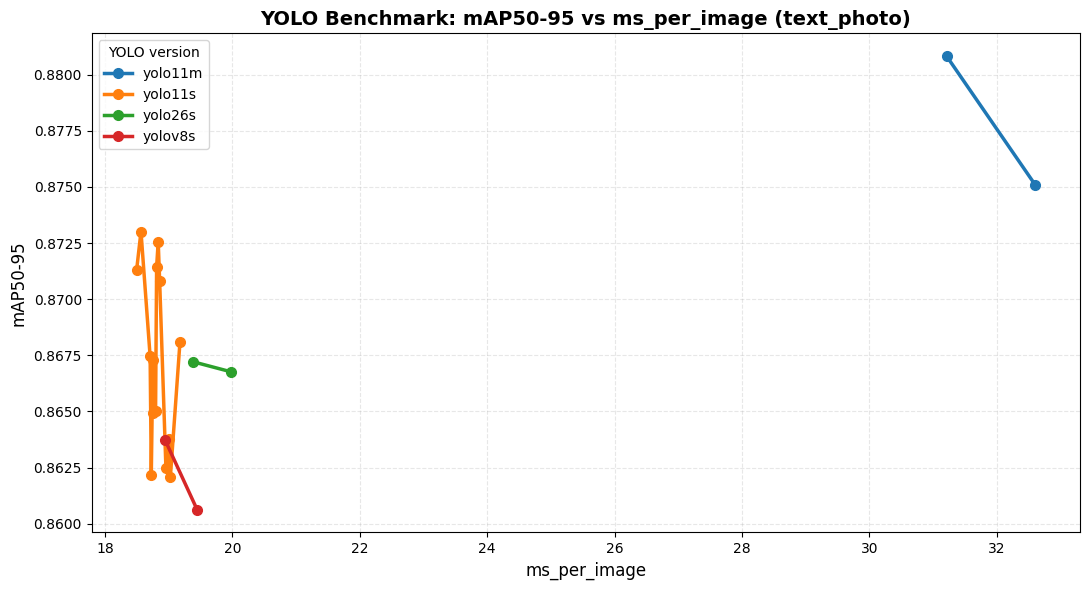

In [59]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50-95", "ms_per_image", df_name= "text_photo")

mAP50 vs ms_per_image

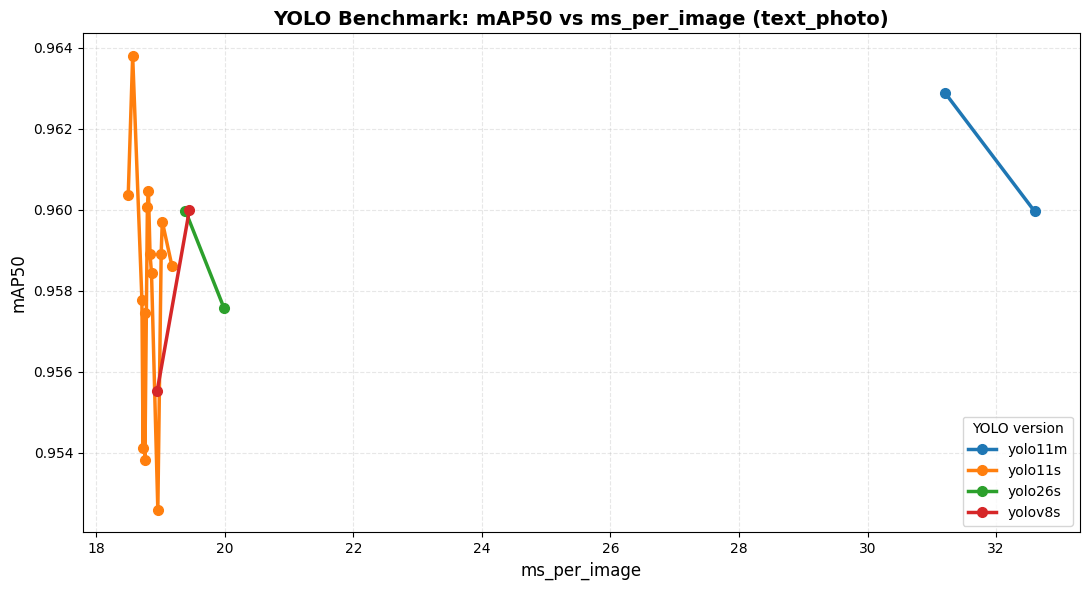

In [58]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50","ms_per_image", df_name= "text_photo")

Precision vs ms_per_image

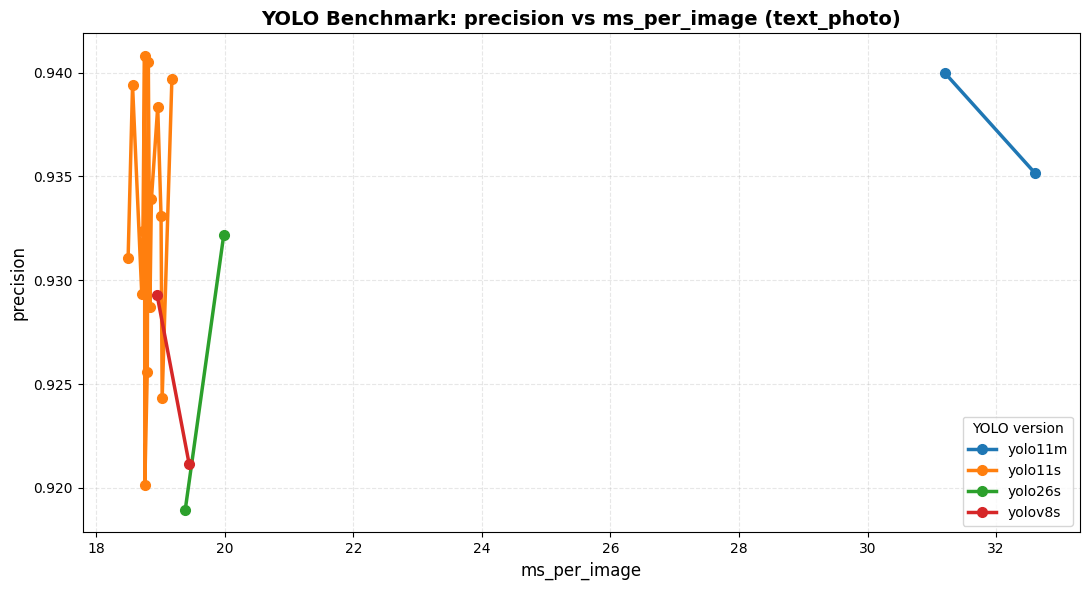

In [60]:
plot_yolo_vs_batch(df_yolo_text_photo, "precision", "ms_per_image",df_name= "text_photo")

Recall vs ms_per_image

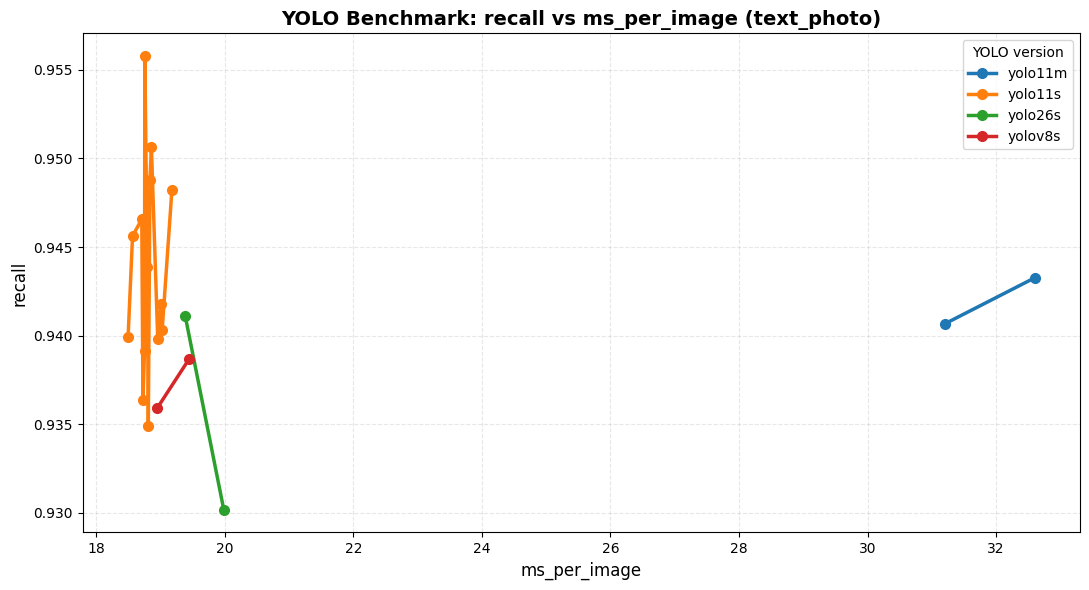

In [61]:
plot_yolo_vs_batch(df_yolo_text_photo, "recall", "ms_per_image",df_name= "text_photo")

Val_box_loss vs ms_per_image

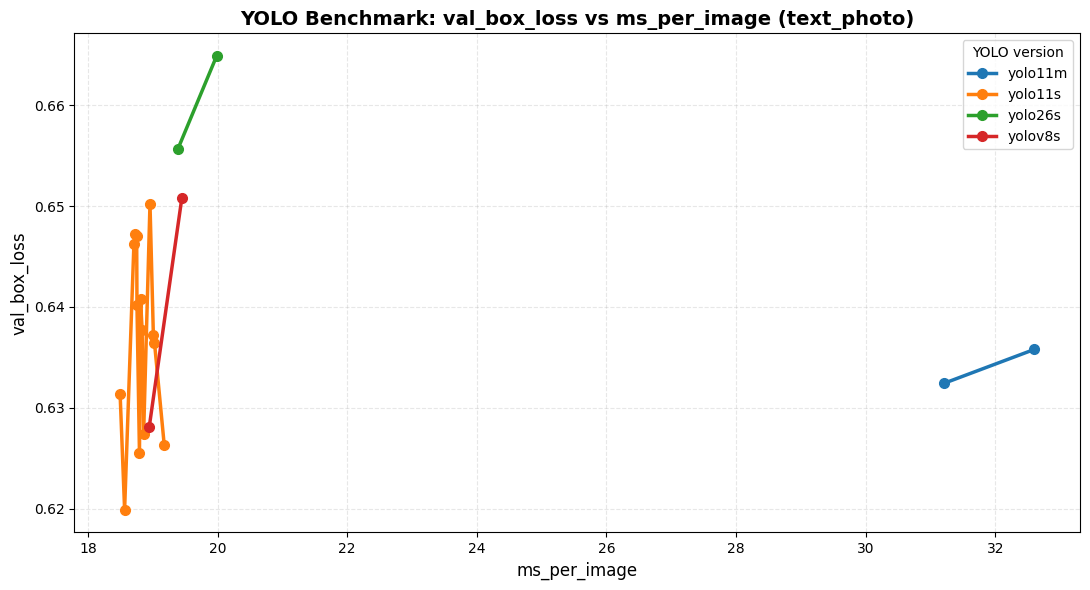

In [62]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_box_loss","ms_per_image",df_name= "text_photo")

Val_cls_loss vs ms_per_image

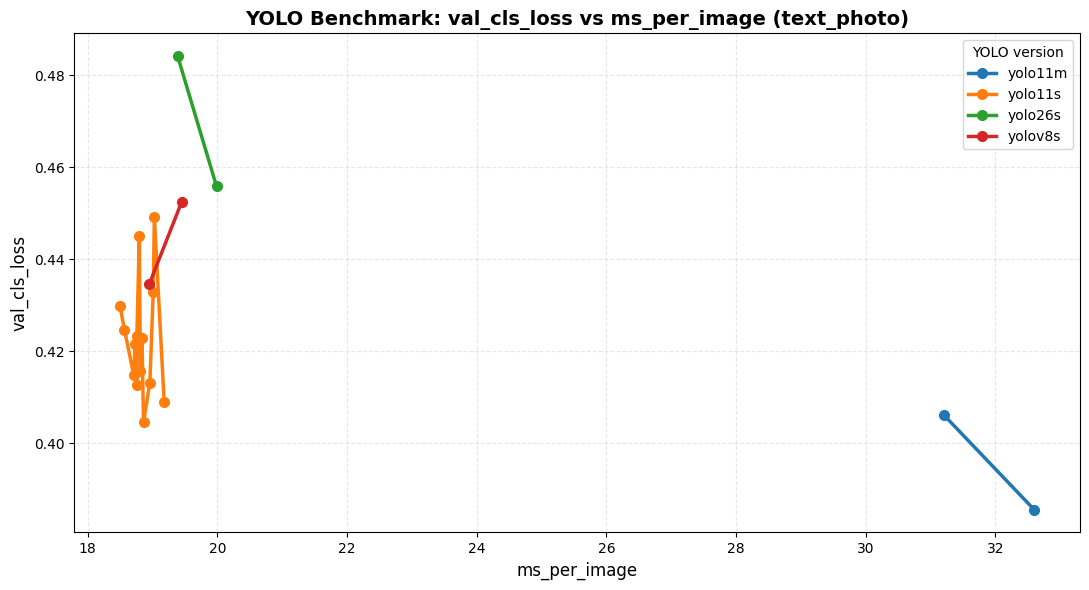

In [63]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_cls_loss", "ms_per_image",df_name= "text_photo")

Val_dfl_loss vs ms_per_image

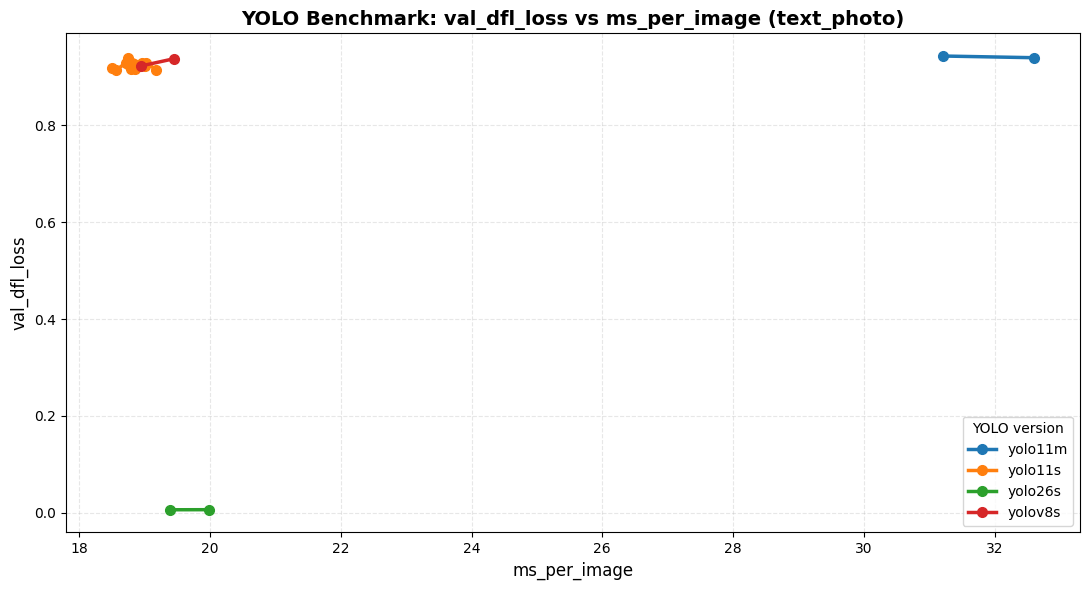

In [64]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_dfl_loss", "ms_per_image",df_name= "text_photo")

#### 1.2.2 YOLO benchmark ordered bar chart

In [68]:
def plot_sorted_bar(
    df,
    y_col,
    group_col="yolo_version",
    title=None,
    df_name=None,
    ascending=True,
    agg_func="max",
    figsize=(10, 6)
):
    """
    Gráfico de barras ordenado com:
    - 1 valor por modelo (agregação)
    - cores diferentes por barra

    Parâmetros:
    - agg_func: "max", "mean", "min", etc.
    """

    # --- garantir 1 valor por modelo ---
    df_grouped = (
        df.groupby(group_col)[y_col]
        .agg(agg_func)
        .reset_index()
    )

    # --- ordenar ---
    df_plot = df_grouped.sort_values(y_col, ascending=ascending)

    plt.figure(figsize=figsize)

    # --- cores diferentes ---
    colors = plt.cm.tab20(np.linspace(0, 1, len(df_plot)))

    plt.bar(df_plot[group_col].astype(str), df_plot[y_col], color=colors)

    # labels
    plt.xlabel(group_col, fontsize=12)
    plt.ylabel(y_col, fontsize=12)

    # título automático
    if title is None:
        base = f"{y_col} ({agg_func}) ordered by {group_col}"
        title = f"{base} ({df_name})" if df_name else base

    plt.title(title, fontsize=14, weight="bold")

    # rodar labels
    plt.xticks(rotation=45, ha="right")

    plt.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()



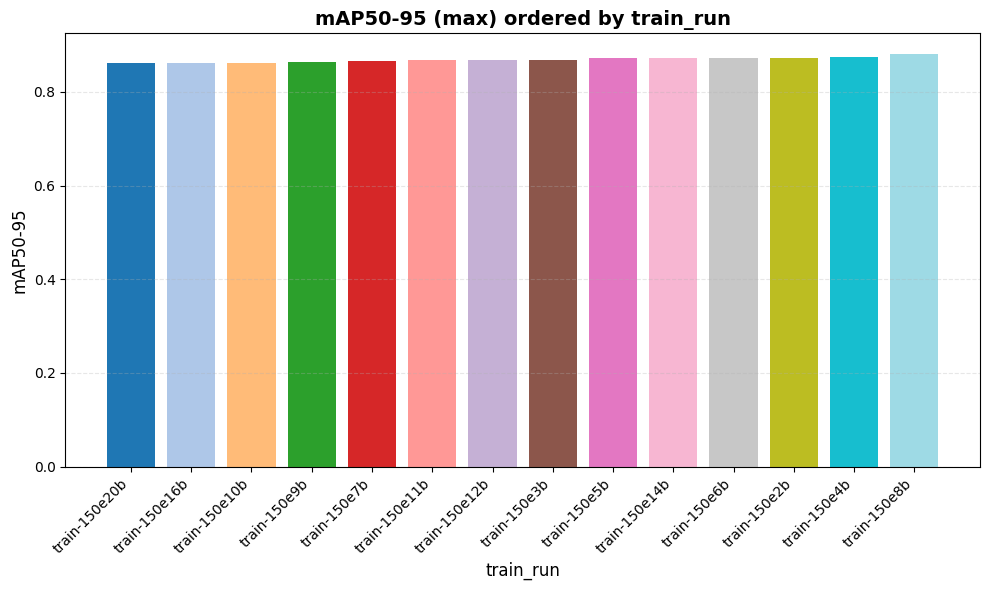

In [69]:
plot_sorted_bar(df_yolo, "mAP50-95", group_col="train_run")
